# Verified scope
Earlier cells analyze the SEC companion experiment; final cells audit actual FMP/GPT-4.1 runs. Historical status tables in SEC cells are superseded by the actual results below. No publication or course submission was performed.

# FinRobot Assignment 1: reproducible audit companion
## tl;dr
This notebook executes the actual upstream deterministic modules with SEC-normalized inputs. It is **not** an FMP or eight-agent experiment. Missing personal API credentials block the full course pipeline.

Observed results: 68 rolling-origin forecasts; MAPE 13.74% for the 5% baseline versus 15.86% for two-year CAGR. Forecast-year validity improves from 60% to 100%. Twenty original-filing checks match. No agent grounding or stability result is claimed.

## Context & Methods
### Key Assumptions
Data cutoff: 2026-10-11. Annual periods, USD amounts in dollars, fiscal-year labels based on period-end year. Trailing two-year CAGR capped at +/-50%; flat margins. Backtest inputs are filtered to filings available at each origin. Upstream mechanical DCF uses 10% WACC, 2.5% terminal growth and synthetic net debt=10% EV. CFO-capex is not validated FCFF. This notebook evaluates arithmetic and source traceability, not tradeable stock returns.

In [1]:
from pathlib import Path
import sys, subprocess, json
import pandas as pd
ROOT = Path.cwd()
assert (ROOT / 'data/sec/NVDA.json').exists(), 'Run from the evidence package directory'
subprocess.run([sys.executable, 'code/prepare_upstream.py'], check=True)
UPSTREAM = ROOT / 'upstream'
print('Python:', sys.version.split()[0])
print('Pinned upstream:', json.loads((ROOT/'upstream_version.json').read_text())['commit'])

Existing upstream preserved. Confirm improvement.patch has already been applied.
Python: 3.12.14
Pinned upstream: 2717499b8e30f242640af08c4ad9afd1113c2d45


## Data
SEC Company Facts snapshots and original NVIDIA/AMD issuer-hosted annual filings are retained. Per-fact lineage, accessions and source links are in audit/sec_fact_lineage.csv. Hashes in run_manifest.json identify the exact snapshots.

In [2]:
sys.path.insert(0,str(ROOT/'code'))
from analyze_sec import main
main(UPSTREAM)

INFO:modules.sensitivity_analyzer:Analyzing revenue growth sensitivity...


INFO:modules.sensitivity_analyzer:✅ Revenue sensitivity analysis complete: 5 scenarios


INFO:modules.sensitivity_analyzer:Analyzing margin sensitivity...


INFO:modules.sensitivity_analyzer:✅ Margin sensitivity analysis complete: 5 scenarios


INFO:modules.valuation_engine:Calculating DCF valuation...


...

INFO:modules.sensitivity_analyzer:Analyzing margin sensitivity...


INFO:modules.sensitivity_analyzer:✅ Margin sensitivity analysis complete: 5 scenarios


INFO:modules.valuation_engine:Calculating DCF valuation...


INFO:modules.valuation_engine:✅ DCF valuation: $216.89


{
  "asof": "2026-10-11",
  "python": "3.12.14 (main, Aug 25 2026, 13:50:33) [Clang 22.1.3 ]",
  "platform": "macOS-14.8.4-arm64-arm-64bit",
  "runtime_seconds": 0.32144866697490215,
  "model_used": null,
  "llm_calls": 0,
  "llm_cost_usd": 0,
  "fmp_calls": 0,
  "status": "API-independent companion completed; course end-to-end pipeline blocked",
  "baseline_mape": 0.1373719283755739,
  "improved_mape": 0.15858024755379685,
  "backtest_n": 68
}
ticker                   name period_end annual_filed  revenue_bn  revenue_yoy  net_margin  fcf_bn  cfo_bn  capex_bn      cagr  mechanical_dcf                                                                                             source               peers latest_quarter_end
  NVDA     NVIDIA Corporation 2026-01-25   2026-02-25     215.938     0.654735    0.556025  96.676 102.718     6.042  0.500000       72.275076 https://www.sec.gov/Archives/edgar/data/1045810/000104581026000021/0001045810-26-000021-index.html  AMD,INTC,AVGO,QCOM         

In [3]:
subprocess.run([sys.executable, 'code/crosscheck_filings.py'], check=True)
checks = pd.read_csv(ROOT/'audit/filing_crosscheck.csv')
assert len(checks) == 20 and checks['delta'].abs().max() < .01
checks[['ticker','metric','sec_value','filing_value','delta']]

20 original-filing cross-checks matched; FMP-vs-filing audit remains pending.


,ticker,metric,sec_value,filing_value,delta
0,NVDA,revenue,2.159380e+11,2.159380e+11,0.0
1,NVDA,cost_of_revenue,6.247500e+10,6.247500e+10,0.0
2,NVDA,sga,4.579000e+09,4.579000e+09,0.0
3,NVDA,gross_profit,1.534630e+11,1.534630e+11,0.0
4,NVDA,eps,4.900000e+00,4.900000e+00,0.0
5,NVDA,net_income,1.200670e+11,1.200670e+11,0.0
6,NVDA,operating_income,1.303870e+11,1.303870e+11,0.0
7,NVDA,cfo,1.027180e+11,1.027180e+11,0.0
8,NVDA,capex,6.042000e+09,6.042000e+09,0.0
9,NVDA,cash,1.060500e+10,1.060500e+10,0.0


## Results
### Coverage and sources

In [4]:
coverage = pd.read_csv(ROOT/'audit/coverage_summary.csv')
coverage[['ticker','period_end','revenue_bn','revenue_yoy','net_margin','fcf_bn']]

,ticker,period_end,revenue_bn,revenue_yoy,net_margin,fcf_bn
0,NVDA,2026-01-25,215.938,0.654735,0.556025,96.676
1,AMD,2025-12-27,34.639,0.343378,0.125148,6.735
2,INTC,2025-12-27,52.853,-0.004670,-0.005052,-4.949
3,AVGO,2025-11-02,63.887,0.238744,0.361983,26.914
4,QCOM,2025-09-28,44.284,0.136595,0.125124,12.820


### Same-company forecast comparison

In [5]:
scorecard = pd.read_csv(ROOT/'audit/forecast_scorecard.csv')
backtest = pd.read_csv(ROOT/'audit/forecast_backtest.csv')
assert (backtest.max_training_filed <= backtest.origin_date).all()
assert (backtest.target_filed > backtest.origin_date).all()
print('Rolling-origin samples:', len(backtest))
print('Pooled MAPE:', backtest[['baseline_ape','improved_ape']].mean().to_dict())
scorecard

Rolling-origin samples: 68
Pooled MAPE: {'baseline_ape': 0.13737192837557388, 'improved_ape': 0.15858024755379682}


,ticker,baseline_ape,improved_ape
0,AMD,0.166566,0.203963
1,AVGO,0.100858,0.098768
2,INTC,0.085035,0.104391
3,NVDA,0.196969,0.207767
4,QCOM,0.122367,0.152877


### Independently reproduce valuation arithmetic

In [6]:
valuation = pd.read_csv(ROOT/'audit/valuation_audit.csv')
assert valuation.delta.abs().max() < 1e-8
valuation[['ticker','engine_price','recomputed_price','delta','terminal_share']]

,ticker,engine_price,recomputed_price,delta,terminal_share
0,NVDA,72.275076,72.275076,0.0,0.536464
1,AMD,75.075397,75.075397,0.0,0.536464
2,INTC,0.000000,0.000000,0.0,0.536464
3,AVGO,103.146841,103.146841,0.0,0.536464
4,QCOM,216.885932,216.885932,0.0,0.536464


### Forecast validity and unit tests

In [7]:
subprocess.run([sys.executable,'code/test_forecasts.py',str(UPSTREAM)],check=True)
rows=[]
for _,c in coverage.iterrows():
 for method,file in [('baseline','upstream_default_forecasts.csv'),('improved','financial_metrics_and_forecasts.csv')]:
  frame=pd.read_csv(ROOT/'analysis'/c.ticker/file)
  rows.extend({'ticker':c.ticker,'method':method,'forecast_year':y,'actual_end':c.period_end,'strictly_future':int(y[:-1])>int(c.period_end[:4])} for y in frame.columns if y.endswith('E'))
validity=pd.DataFrame(rows)
validity.to_csv(ROOT/'audit/temporal_validity.csv',index=False)
validity.groupby('method').strictly_future.mean()

....
----------------------------------------------------------------------
Ran 4 tests in 0.002s

OK


method
baseline    0.6
improved    1.0
Name: strictly_future, dtype: float64

### Render source-backed findings

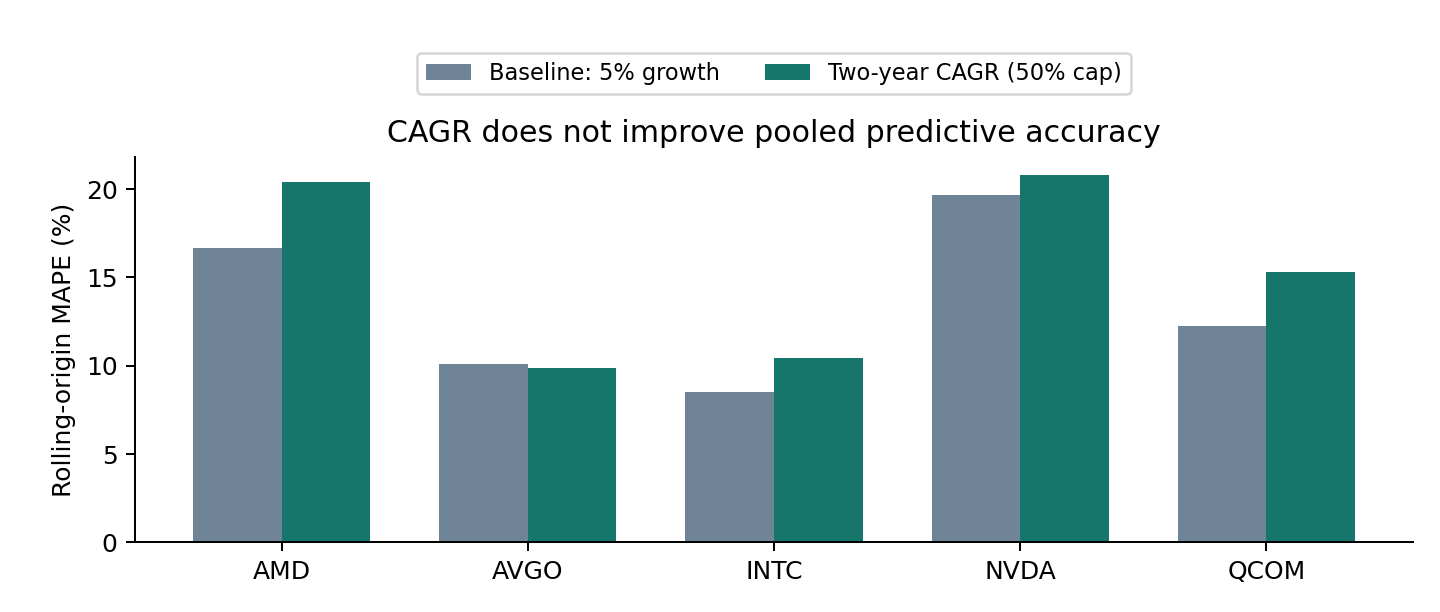

In [8]:
# Report already generated and verified; rerunning audits does not overwrite it.
from IPython.display import Image, display
display(Image(filename=str(ROOT/'charts/forecast_backtest.png')))

## Takeaways
The patch fixes forecast-year chronology, but the simple CAGR estimator is less accurate on the pooled historical sample. This does not establish forecasting superiority. The upstream forecast EBITDA definition omits R&D, and its synthetic net debt and negative-FCF perpetuity make DCF target prices unsuitable for an investment recommendation.

Full assignment blockers: FMP/OpenAI access, real baseline and improved agent reports, complete claim-level grounding, frozen-input three-run stability, Medium publication and final student submission. Blank values in status tables mean **not run**, not zero error. See README.md for the requirement-by-requirement checklist.

## Actual FMP execution update
Actual GPT-4.1 agent generation succeeded after credit was added. The financial audit below is separate from prose grounding.

In [9]:
fmp_audit = pd.read_csv(ROOT / 'audit/fmp_data_audit.csv')
display(fmp_audit)
display(pd.read_csv(ROOT / 'audit/fmp_valuation_audit.csv'))
assert len(fmp_audit)==20

,ticker,metric,fiscal_year,period_end,pipeline_value,filing_reference_value,delta,unit,verdict,explanation,source_url,raw_pipeline_file
0,NVDA,Revenue,2026,2026-01-25,2.159380e+11,2.159380e+11,0.000000e+00,USD,Matched within published rounding,Direct filing match.,https://www.sec.gov/Archives/edgar/data/104581...,actual_runs/baseline/NVDA/analysis/financial_m...
1,NVDA,Cost of Operations,2026,2026-01-25,6.247500e+10,6.247500e+10,0.000000e+00,USD,Matched within published rounding,Direct filing match.,https://www.sec.gov/Archives/edgar/data/104581...,actual_runs/baseline/NVDA/analysis/financial_m...
2,NVDA,SG&A,2026,2026-01-25,4.579000e+09,4.579000e+09,0.000000e+00,USD,Matched within published rounding,Direct filing match.,https://www.sec.gov/Archives/edgar/data/104581...,actual_runs/baseline/NVDA/analysis/financial_m...
3,NVDA,Contribution Profit,2026,2026-01-25,1.534630e+11,1.534630e+11,0.000000e+00,USD,Matched within published rounding,Direct filing match.,https://www.sec.gov/Archives/edgar/data/104581...,actual_runs/baseline/NVDA/analysis/financial_m...
4,NVDA,Contribution Margin,2026,2026-01-25,7.110000e+01,7.106808e+01,3.191564e-02,percentage points,Matched within published rounding,Compared with original filing/SEC facts; perce...,https://www.sec.gov/Archives/edgar/data/104581...,actual_runs/baseline/NVDA/analysis/financial_m...
5,NVDA,SG&A Margin,2026,2026-01-25,2.100000e+00,2.120516e+00,-2.051607e-02,percentage points,Matched within published rounding,Compared with original filing/SEC facts; perce...,https://www.sec.gov/Archives/edgar/data/104581...,actual_runs/baseline/NVDA/analysis/financial_m...
6,NVDA,Revenue Growth,2026,2026-01-25,6.550000e+01,6.547354e+01,2.646421e-02,percentage points,Matched within published rounding,Compared with original filing/SEC facts; perce...,https://www.sec.gov/Archives/edgar/data/104581...,actual_runs/baseline/NVDA/analysis/financial_m...
7,NVDA,EPS,2026,2026-01-25,4.930000e+00,4.930000e+00,0.000000e+00,USD/share,Matched within published rounding,Pipeline uses basic EPS (not diluted): origina...,https://www.sec.gov/Archives/edgar/data/104581...,actual_runs/baseline/NVDA/analysis/financial_m...
8,NVDA,EBITDA,2026,2026-01-25,1.445520e+11,1.332300e+11,1.132200e+10,USD,Definition difference; reconciliation required,"Reference is operating income + filing D&A, an...",https://www.sec.gov/Archives/edgar/data/104581...,actual_runs/baseline/NVDA/analysis/financial_m...
9,NVDA,EBITDA Margin,2026,2026-01-25,6.690000e+01,6.169827e+01,5.201735e+00,percentage points,Definition difference; reconciliation required,"Reference is operating income + filing D&A, an...",https://www.sec.gov/Archives/edgar/data/104581...,actual_runs/baseline/NVDA/analysis/financial_m...


,ticker,end,base_fcf,share_basis,shares,engine_price,recomputed_price,difference,actual_balance_net_debt,synthetic_net_debt,wacc,terminal_growth,source,status
0,NVDA,2026-01-25,9.667600e+10,FY weighted-average diluted shares; not curren...,2.451400e+10,71.655929,71.655929,0.000000e+00,807000000,1.951748e+11,0.1,0.025,"FMP stable statements, preserved raw CSVs",Arithmetic verified; mechanical valuation only
1,AMD,2025-12-27,6.735000e+09,FY weighted-average diluted shares; not curren...,1.636000e+09,74.800059,74.800059,1.421085e-14,-1067000000,1.359699e+10,0.1,0.025,"FMP stable statements, preserved raw CSVs",Arithmetic verified; mechanical valuation only
2,INTC,2025-12-27,-4.949000e+09,FY weighted-average diluted shares; not curren...,4.856000e+09,0.000000,0.000000,0.000000e+00,32320000000,-9.991313e+09,0.1,0.025,"FMP stable statements, preserved raw CSVs",Arithmetic verified; mechanical valuation only
3,AAPL,2025-09-27,9.876700e+10,FY weighted-average diluted shares; not curren...,1.500470e+10,119.600301,119.600301,0.000000e+00,76443000000,1.993963e+11,0.1,0.025,"FMP stable statements, preserved raw CSVs",Arithmetic verified; mechanical valuation only
4,MSFT,2026-06-30,6.698700e+10,FY weighted-average diluted shares; not curren...,7.453000e+09,163.307845,163.307845,-5.684342e-14,107873300000,1.352370e+11,0.1,0.025,"FMP stable statements, preserved raw CSVs",Arithmetic verified; mechanical valuation only


## Actual agent execution, grounding, stability and cost
Grounding is provisional model-based extraction plus documented corrections. Review evidence and limitations before interpreting the rates.

In [10]:
for file in ['actual_execution_summary.csv','grounding_rates.csv','grounding_review_corrections.csv','stability_actual.csv','api_cost_ledger.csv']:
    print(file)
    display(pd.read_csv(ROOT / 'audit' / file))
assert len(pd.read_csv(ROOT/'audit/grounding_rates.csv'))==24
assert len(pd.read_csv(ROOT/'audit/stability_actual.csv'))==3

actual_execution_summary.csv


,ticker,sections,step1_seconds,step2_seconds,html_reports
0,NVDA,8,37.840362,2.242736,5
1,AMD,8,37.037928,2.106226,5
2,INTC,8,39.827434,2.201744,5
3,AAPL,8,34.445777,1.891786,5
4,MSFT,8,33.625273,1.876015,5
5,GOOGL,8,36.007758,1.961646,5


grounding_rates.csv


,ticker,section,total,supported,unsupported,contradicted,grounding_rate
0,AMD,company_overview,28,4,24,0,0.142857
1,AMD,competitor_analysis,23,4,19,0,0.173913
2,AMD,investment_overview,24,12,12,0,0.500000
3,AMD,major_takeaways,24,12,12,0,0.500000
4,AMD,news_summary,25,7,18,0,0.280000
5,AMD,risks,35,7,28,0,0.200000
6,AMD,tagline,9,3,6,0,0.333333
7,AMD,valuation_overview,29,17,12,0,0.586207
8,INTC,company_overview,43,5,38,0,0.116279
9,INTC,competitor_analysis,24,1,23,0,0.041667


grounding_review_corrections.csv


,ticker,section,claim,old_label,new_label,review_reason
0,NVDA,major_takeaways,NVIDIA’s jump from $26.9B in 2023A to $60.9B i...,Supported,Unsupported,Numeric component is supported but asserted cu...
1,NVDA,news_summary,NVIDIA's forward guidance suggests revenue may...,Supported,Unsupported,Historical 2025A revenue is not forward guidan...
2,NVDA,news_summary,NVIDIA's EBITDA and margins are forecast to co...,Supported,Unsupported,"Reviewer cited actual A columns, not forecast ..."
3,NVDA,news_summary,Peers AMD and Intel lag considerably in EBITDA...,Supported,Unsupported,Peer EBITDA supports relative comparison but d...
4,NVDA,tagline,NVIDIA Corporation has industry-leading profit...,Supported,Unsupported,Classification contradicted its own reasoning:...


stability_actual.csv


,run,rating,target_price,top3_risks,input,model
0,1,NaN,NaN,"[{""label"": ""Market Risk"", ""quote"": ""NVIDIA fac...",Exact frozen user_prompt + same upstream agent...,gpt-4.1
1,2,NaN,NaN,"[{""label"": ""Market Risk"", ""quote"": ""NVIDIA\u20...",Exact frozen user_prompt + same upstream agent...,gpt-4.1
2,3,NaN,NaN,"[{""label"": ""Market Risk"", ""quote"": ""NVIDIA's g...",Exact frozen user_prompt + same upstream agent...,gpt-4.1


api_cost_ledger.csv


,file,input_tokens,cached_input_tokens,output_tokens,usd
0,actual_runs/evaluation/NVDA_investment_overvie...,2234,0,2475,0.024268
1,actual_runs/evaluation/AMD_major_takeaways_cla...,2262,0,2225,0.022324
2,actual_runs/evaluation/INTC_investment_overvie...,2249,0,1686,0.017986
3,actual_runs/evaluation/NVDA_competitor_analysi...,2470,1408,1902,0.018044
4,actual_runs/evaluation/INTC_competitor_analysi...,2469,0,1354,0.015770
...,...,...,...,...,...
94,actual_runs/improved/NVDA/agent_evidence/news_...,1898,0,484,0.007668
95,actual_runs/improved/NVDA/agent_evidence/tagli...,1518,0,65,0.003556
96,actual_runs/improved/NVDA/agent_evidence/compa...,2014,0,1180,0.013468
97,actual_runs/improved/NVDA/agent_evidence/major...,1716,0,541,0.007760
